<a href="https://colab.research.google.com/github/ali-liyakat/100_days_Deep_Learning/blob/main/06_CNN/07_Dog_vs_Cat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Dog vs Cat Classification : CNN

### Dataset: Dogs vs. Cats

**Source:** Kaggle  
**Dataset Link:** [Dogs vs. Cats Dataset](https://www.kaggle.com/datasets/salader/dogsvscats)

**Description:** This dataset contains images of dogs and cats for a binary image classification task using deep learning and Convolutional Neural Networks (CNNs).

**Task:** Classify images into two categories: `Dogs` and `Cats`.

**Access Method:** The dataset is accessed programmatically using `kagglehub`, without manually downloading files through a browser.

In [1]:
import kagglehub
from pathlib import Path

# Automatically download and cache the dataset
dataset_path = kagglehub.dataset_download(
    "salader/dogsvscats"
)

dataset_path = Path(dataset_path)

print("Dataset location:", dataset_path)

# Display the folder structure
for item in list(dataset_path.iterdir()):
    print(item.name)

100%|██████████| 1.06G/1.06G [00:10<00:00, 109MB/s]

Extracting files...


Dataset location: /root/.cache/kagglehub/datasets/salader/dogsvscats/versions/1
catsvsdogs
test
train


In [4]:
from pathlib import Path

dataset_path = Path(
    "/root/.cache/kagglehub/datasets/salader/dogsvscats/versions/1"
)

train_dir = dataset_path / "train"
test_dir = dataset_path / "test"

print("Training directory exists:", train_dir.exists())
print("Testing directory exists:", test_dir.exists())

print("\nTraining classes:", [p.name for p in train_dir.iterdir()])
print("Testing classes:", [p.name for p in test_dir.iterdir()])

Training directory exists: True
Testing directory exists: True

Training classes: ['dogs', 'cats']
Testing classes: ['dogs', 'cats']


In [5]:
from pathlib import Path

train_dir = dataset_path / "train"
test_dir = dataset_path / "test"

print("Training folders:")
for folder in train_dir.iterdir():
    print(folder.name, "->", "Folder" if folder.is_dir() else "File")

print("\nTesting folders:")
for folder in test_dir.iterdir():
    print(folder.name, "->", "Folder" if folder.is_dir() else "File")

Training folders:
dogs -> Folder
cats -> Folder

Testing folders:
dogs -> Folder
cats -> Folder


In [6]:
import tensorflow as tf

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(150, 150),
    batch_size=32,
    label_mode="binary",
    shuffle=True
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=(150, 150),
    batch_size=32,
    label_mode="binary",
    shuffle=False
)

print("Classes:", train_ds.class_names)

Found 20000 files belonging to 2 classes.
Found 5000 files belonging to 2 classes.
Classes: ['cats', 'dogs']


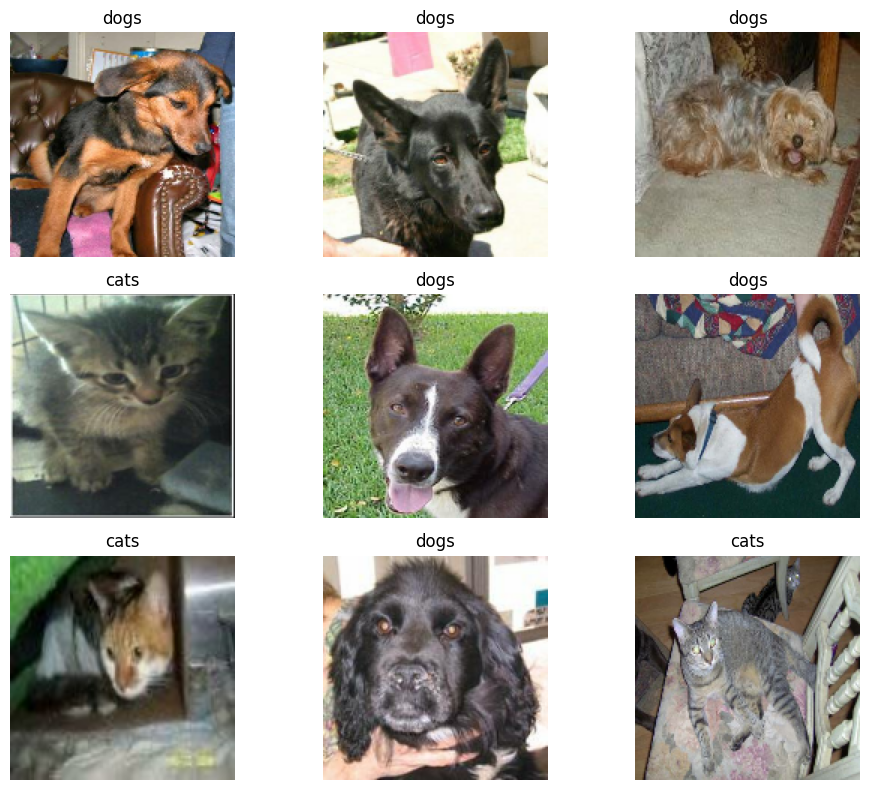

In [7]:
import matplotlib.pyplot as plt

# Get one batch of training images
images, labels = next(iter(train_ds))

# Display 9 images
plt.figure(figsize=(10, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)

    plt.imshow(images[i].numpy().astype("uint8"))

    label = int(labels[i].numpy()[0])
    class_name = train_ds.class_names[label]

    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [8]:
# Normalize pixel values from [0, 255] to [0, 1]
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(
    lambda images, labels: (normalization_layer(images), labels)
)

test_ds = test_ds.map(
    lambda images, labels: (normalization_layer(images), labels)
)

# Verify the pixel values
for images, labels in train_ds.take(1):
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [9]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

print("Dataset pipelines optimized!")

Dataset pipelines optimized!


In [10]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(150, 150, 3)),

    # Convolutional block 1
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convolutional block 2
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convolutional block 3
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Classification head
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,828,481 (18.42 MB)

 Trainable params: 4,828,481 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [12]:
history = model.fit(
    train_ds,
    epochs=10,
    validation_data=test_ds
)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 36s 43ms/step - accuracy: 0.6531 - loss: 0.6143 - val_accuracy: 0.7438 - val_loss: 0.5117
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 25s 40ms/step - accuracy: 0.7620 - loss: 0.5011 - val_accuracy: 0.7970 - val_loss: 0.4467
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 25s 39ms/step - accuracy: 0.8016 - loss: 0.4310 - val_accuracy: 0.7830 - val_loss: 0.4535
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 25s 40ms/step - accuracy: 0.8403 - loss: 0.3621 - val_accuracy: 0.8332 - val_loss: 0.3740
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 25s 39ms/step - accuracy: 0.8673 - loss: 0.3078 - val_accuracy: 0.8520 - val_loss: 0.3438
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 25s 39ms/step - accuracy: 0.8992 - loss: 0.2429 - val_accuracy: 0.8300 - val_loss: 0.4018
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 25s 40ms/step - accuracy: 0.9213 - loss: 0.1963 - val_accuracy: 0.8514 - val_loss: 0.3961
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 41s 40ms/step - accuracy: 0.9342 - loss: 0.1608 - 

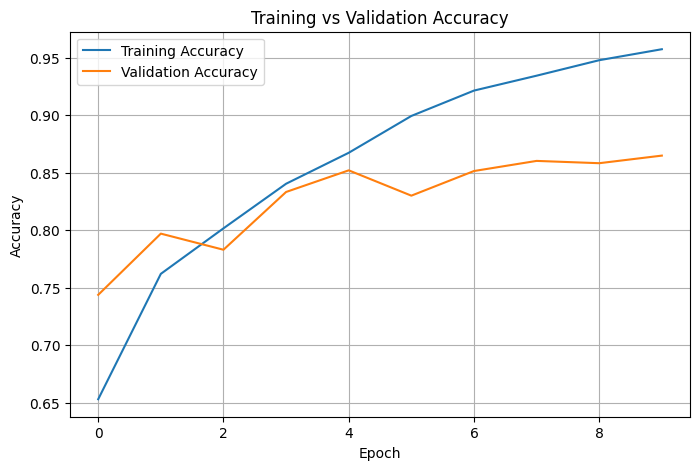

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

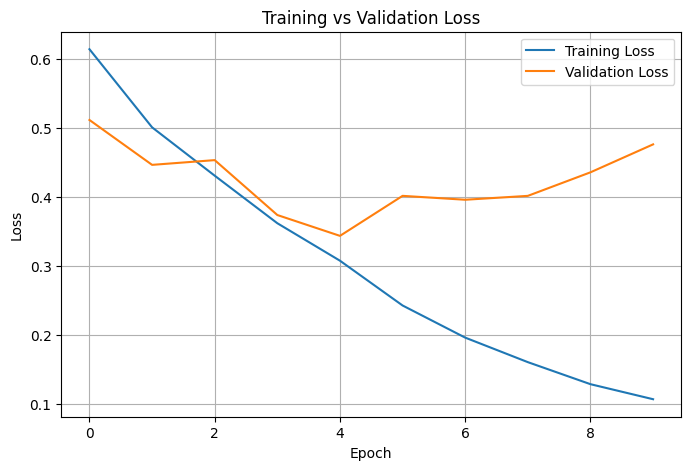

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [15]:
test_loss, test_accuracy = model.evaluate(test_ds)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - accuracy: 0.8648 - loss: 0.4764
Test Loss: 0.4764
Test Accuracy: 0.8648
Test Accuracy: 86.48%


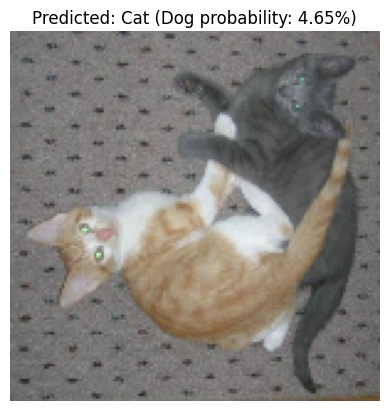

Image: cat.11736.jpg
Prediction: Cat
Dog probability: 0.0465


In [16]:
import numpy as np
from pathlib import Path
from tensorflow.keras.utils import load_img, img_to_array

# Select an image from either class
image_path = next((test_dir / "cats").glob("*"))

# To test a dog instead, use:
# image_path = next((test_dir / "dogs").glob("*"))

img = load_img(image_path, target_size=(150, 150))
img_array = img_to_array(img) / 255.0
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array, verbose=0)[0][0]

# Labels are alphabetically ordered: cats=0, dogs=1
predicted_class = "Dog" if prediction >= 0.5 else "Cat"

plt.imshow(img)
plt.title(
    f"Predicted: {predicted_class} "
    f"(Dog probability: {prediction:.2%})"
)
plt.axis("off")
plt.show()

print("Image:", image_path.name)
print("Prediction:", predicted_class)
print(f"Dog probability: {prediction:.4f}")

In [17]:
model.save("dogs_vs_cats_cnn.keras")

print("Model saved successfully!")

Model saved successfully!


In [18]:
from tensorflow.keras.models import load_model

loaded_model = load_model("dogs_vs_cats_cnn.keras")

print("Model loaded successfully!")

Model loaded successfully!


### Data Augmentation

In [19]:
import tensorflow as tf
from tensorflow.keras import layers, models

data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(
        height_factor=0.1,
        width_factor=0.1
    )
], name="data_augmentation")

print("Data augmentation layer created!")

Data augmentation layer created!


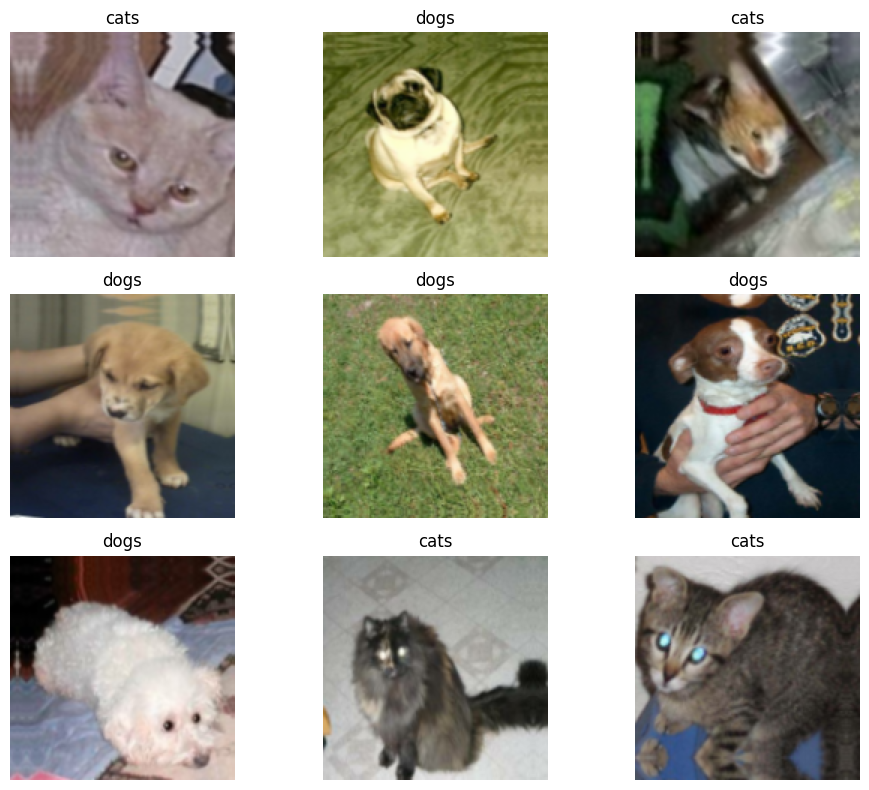

In [20]:
import matplotlib.pyplot as plt
import tensorflow as tf

class_names = ["cats", "dogs"]

images, labels = next(iter(train_ds))

plt.figure(figsize=(10, 8))

for i in range(9):
    augmented_image = data_augmentation(
        tf.expand_dims(images[i], axis=0),
        training=True
    )[0]

    plt.subplot(3, 3, i + 1)
    plt.imshow(tf.clip_by_value(augmented_image, 0, 1))

    label = int(labels[i].numpy()[0])
    plt.title(class_names[label])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [21]:
augmented_model = models.Sequential([
    layers.Input(shape=(150, 150, 3)),

    # Random transformations during training
    data_augmentation,

    # CNN block 1
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # CNN block 2
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # CNN block 3
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Classification head
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
], name="augmented_cnn")

augmented_model.summary()

Model: "augmented_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,828,481 (18.42 MB)

 Trainable params: 4,828,481 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
augmented_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Augmented CNN compiled!")

Augmented CNN compiled!


In [24]:
history_aug = augmented_model.fit(
    train_ds,
    epochs=10,
    validation_data=test_ds
)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 27s 44ms/step - accuracy: 0.7447 - loss: 0.5230 - val_accuracy: 0.7676 - val_loss: 0.4892
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 27s 43ms/step - accuracy: 0.7639 - loss: 0.4915 - val_accuracy: 0.8054 - val_loss: 0.4249
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 27s 43ms/step - accuracy: 0.7762 - loss: 0.4785 - val_accuracy: 0.8126 - val_loss: 0.4088
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 27s 43ms/step - accuracy: 0.7879 - loss: 0.4539 - val_accuracy: 0.8012 - val_loss: 0.4242
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 26s 42ms/step - accuracy: 0.7977 - loss: 0.4380 - val_accuracy: 0.8274 - val_loss: 0.3908
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 27s 42ms/step - accuracy: 0.8006 - loss: 0.4279 - val_accuracy: 0.8160 - val_loss: 0.4019
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 27s 43ms/step - accuracy: 0.8172 - loss: 0.4099 - val_accuracy: 0.8498 - val_loss: 0.3365
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 27s 43ms/step - accuracy: 0.8253 - loss: 0.3940 - 

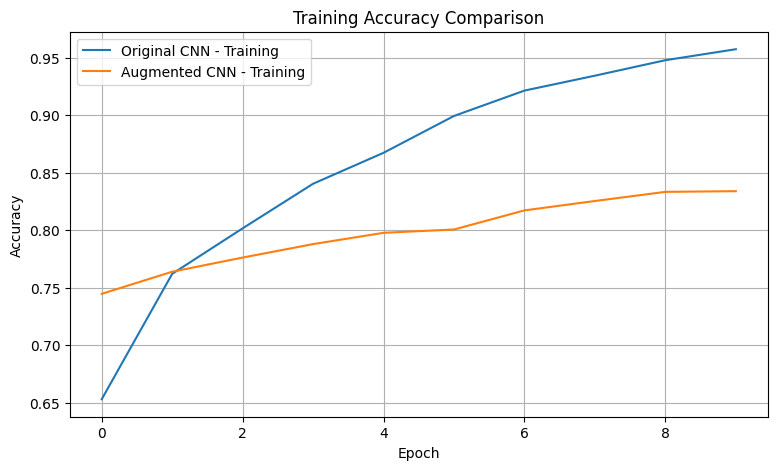

In [25]:
plt.figure(figsize=(9, 5))

plt.plot(
    history.history["accuracy"],
    label="Original CNN - Training"
)
plt.plot(
    history_aug.history["accuracy"],
    label="Augmented CNN - Training"
)

plt.title("Training Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

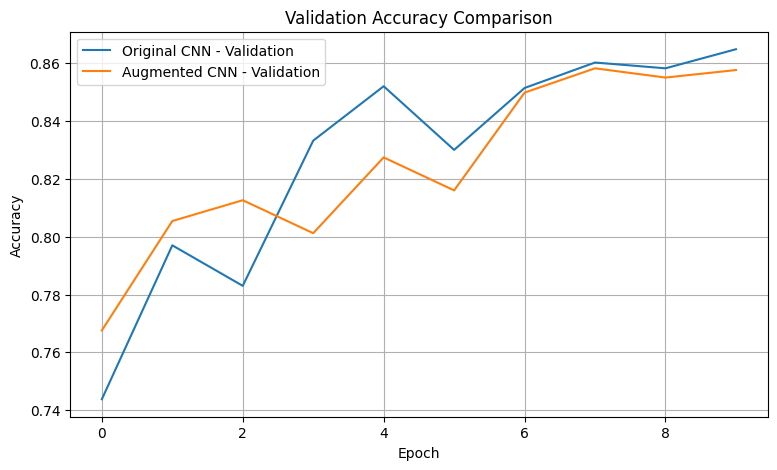

In [26]:
plt.figure(figsize=(9, 5))

plt.plot(
    history.history["val_accuracy"],
    label="Original CNN - Validation"
)
plt.plot(
    history_aug.history["val_accuracy"],
    label="Augmented CNN - Validation"
)

plt.title("Validation Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

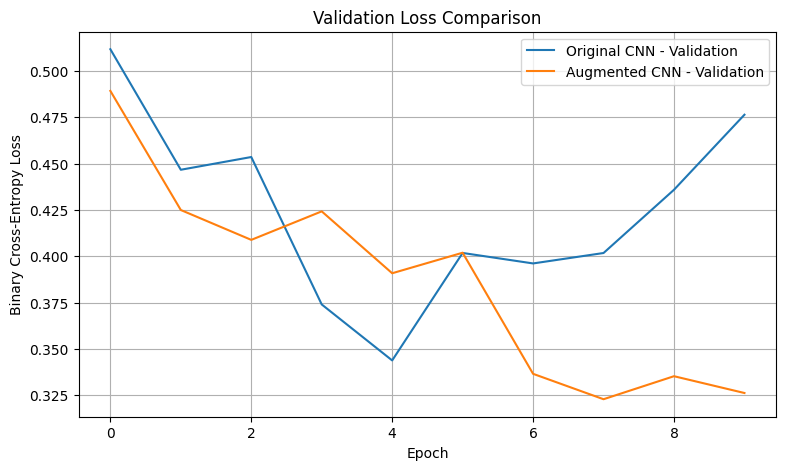

In [27]:
plt.figure(figsize=(9, 5))

plt.plot(
    history.history["val_loss"],
    label="Original CNN - Validation"
)
plt.plot(
    history_aug.history["val_loss"],
    label="Augmented CNN - Validation"
)

plt.title("Validation Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(True)
plt.show()

In [28]:
test_loss_aug, test_accuracy_aug = augmented_model.evaluate(test_ds)

print(f"Augmented Model Test Loss: {test_loss_aug:.4f}")
print(f"Augmented Model Test Accuracy: {test_accuracy_aug:.4f}")
print(f"Augmented Model Accuracy: {test_accuracy_aug * 100:.2f}%")

157/157 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - accuracy: 0.8576 - loss: 0.3262
Augmented Model Test Loss: 0.3262
Augmented Model Test Accuracy: 0.8576
Augmented Model Accuracy: 85.76%
